In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
def multiple(multiple,start,end):
    sum_of_multiples = 0
    multiples = []
    # Iterate through the range
    for i in range(start, end + 1):
        if i % multiple == 0:
            multiples.append(i)
            sum_of_multiples += i
    print(f"Multiples of {multiple}:", multiples)
    print("Sum of Multiples:", sum_of_multiples)

In [23]:
multiple(3,250,300)

Multiples of 3: [252, 255, 258, 261, 264, 267, 270, 273, 276, 279, 282, 285, 288, 291, 294, 297, 300]
Sum of Multiples: 4692


#### Parent grid e_we, e_sn calculations

In [4]:
def resolution_extent(mid_lon, mid_lat, resolution,lat_extent,lon_extent):
    p_lons = mid_lon + np.arange(-(lon_extent/2), (lon_extent/2) + 1) * resolution
    p_lats = mid_lat + np.arange(-(lat_extent/2), (lat_extent/2) + 1) * resolution
    print('Min Lon:',p_lons.min(),'Max Lon:',p_lons.max())
    print('Min Lat:',p_lats.min(),'Max Lat:',p_lats.max())
    print('Lons(parent:e_we):',p_lons.shape)
    print('Lats(parent:e_sn):',p_lats.shape)
    print('Lons:',p_lons)
    print('Lats:',p_lats)
    return p_lons.min(), p_lons.max(), p_lats.min(), p_lats.max(), p_lons, p_lats

In [5]:
a = resolution_extent(mid_lon=79,mid_lat=23,resolution=0.25,lat_extent=120,lon_extent=138)

Min Lon: 61.75 Max Lon: 96.25
Min Lat: 8.0 Max Lat: 38.0
Lons(parent:e_we): (139,)
Lats(parent:e_sn): (121,)
Lons: [61.75 62.   62.25 62.5  62.75 63.   63.25 63.5  63.75 64.   64.25 64.5
 64.75 65.   65.25 65.5  65.75 66.   66.25 66.5  66.75 67.   67.25 67.5
 67.75 68.   68.25 68.5  68.75 69.   69.25 69.5  69.75 70.   70.25 70.5
 70.75 71.   71.25 71.5  71.75 72.   72.25 72.5  72.75 73.   73.25 73.5
 73.75 74.   74.25 74.5  74.75 75.   75.25 75.5  75.75 76.   76.25 76.5
 76.75 77.   77.25 77.5  77.75 78.   78.25 78.5  78.75 79.   79.25 79.5
 79.75 80.   80.25 80.5  80.75 81.   81.25 81.5  81.75 82.   82.25 82.5
 82.75 83.   83.25 83.5  83.75 84.   84.25 84.5  84.75 85.   85.25 85.5
 85.75 86.   86.25 86.5  86.75 87.   87.25 87.5  87.75 88.   88.25 88.5
 88.75 89.   89.25 89.5  89.75 90.   90.25 90.5  90.75 91.   91.25 91.5
 91.75 92.   92.25 92.5  92.75 93.   93.25 93.5  93.75 94.   94.25 94.5
 94.75 95.   95.25 95.5  95.75 96.   96.25]
Lats: [ 8.    8.25  8.5   8.75  9.    9.25  9.5  

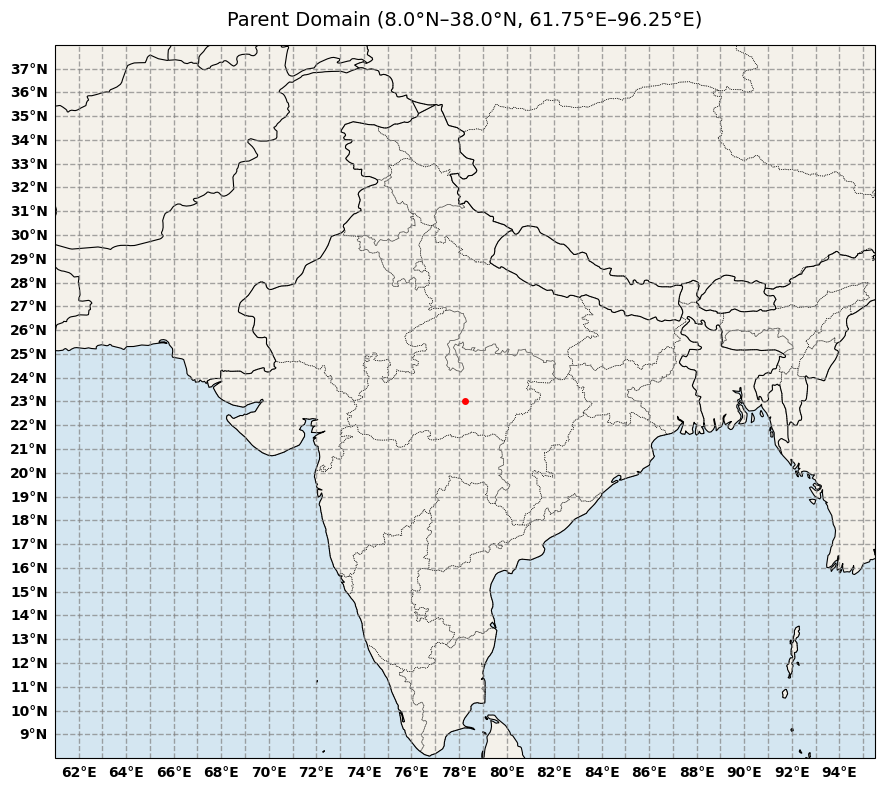

In [6]:
mid_lon=79
mid_lat=23


import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# 1. Define your latitude and longitude limits [min_lon, max_lon, min_lat, max_lat]
# Example: Central India / Madhya Pradesh region
lon_min, lon_max = a[0], a[1]
lat_min, lat_max = a[2], a[3]

# 2. Set up the figure and map projection
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# 3. Apply the coordinate limits to the map
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# 4. Add basic geographic features for context
ax.add_feature(cfeature.LAND, facecolor="#f4f1ea")
ax.add_feature(cfeature.OCEAN, facecolor="#d4e6f1")
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle="-", linewidth=0.8)
ax.add_feature(
    cfeature.STATES, linestyle=":", linewidth=0.5
)  # State/province borders

# 5. Add gridlines highlighting whole-number lat/lon
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=1.0,
    color="gray",
    alpha=0.7,
    linestyle="--",
)
# 6. Add center lat/lon
ax.plot(
    mid_lon,
    mid_lat,
    marker='o',
    color='red',
    markersize=4,
    transform=ccrs.PlateCarree(),
)

# Turn off labels on the top and right edges for a cleaner look
gl.top_labels = False
gl.right_labels = False

# Force gridlines to appear strictly at whole numbers (1-degree steps)
gl.xlocator = mticker.FixedLocator(np.arange(lon_min, lon_max + 1, 1))
gl.ylocator = mticker.FixedLocator(np.arange(lat_min, lat_max + 1, 1))

# Format the labels as whole numbers with degree symbols
gl.xformatter = mticker.FuncFormatter(lambda x, pos: f"{int(x)}°E")
gl.yformatter = mticker.FuncFormatter(lambda y, pos: f"{int(y)}°N")

# Style the gridline text
gl.xlabel_style = {"size": 10, "weight": "bold", "color": "black"}
gl.ylabel_style = {"size": 10, "weight": "bold", "color": "black"}

plt.title(
        f"Parent Domain ({lat_min}°N–{lat_max}°N, {lon_min}°E–{lon_max}°E)",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

#### Nested domain calculations

In [22]:
# Calculate i and j Parent Start
# Provide your imaginery i and j start values from the map above
i = 72
j = 19 

print('i_parent_start:',(np.where(np.array(a[4]) == i))[0]+1)
print('j_parent_start:',(np.where(np.array(a[5]) == j))[0]+1)


i_parent_start: [42]
j_parent_start: [45]


In [31]:
# dx and dy of nested domain
n1_lon_min = 72
n1_lon_max = 84
n1_lat_min = 19
n1_lat_max = 29

print('lon extension in degrees:', n1_lon_max-n1_lon_min)
print('Lat extension in degrees:', n1_lat_max-n1_lat_min)

n1_lats = np.linspace(n1_lon_min,n1_lon_max,283)
n1_lons = np.linspace(n1_lat_min,n1_lat_max,261)

print('Nest-1 e_we:',n1_lats.shape)
print('Nest-1 e_sn:',n1_lons.shape)

print('Nest-1 Lons:',n1_lats)
print('Nest-1 Lats:',n1_lons)

lon extension in degrees: 12
Lat extension in degrees: 10
Nest-1 e_we: (283,)
Nest-1 e_sn: (261,)
Nest-1 Lons: [72.         72.04255319 72.08510638 72.12765957 72.17021277 72.21276596
 72.25531915 72.29787234 72.34042553 72.38297872 72.42553191 72.46808511
 72.5106383  72.55319149 72.59574468 72.63829787 72.68085106 72.72340426
 72.76595745 72.80851064 72.85106383 72.89361702 72.93617021 72.9787234
 73.0212766  73.06382979 73.10638298 73.14893617 73.19148936 73.23404255
 73.27659574 73.31914894 73.36170213 73.40425532 73.44680851 73.4893617
 73.53191489 73.57446809 73.61702128 73.65957447 73.70212766 73.74468085
 73.78723404 73.82978723 73.87234043 73.91489362 73.95744681 74.
 74.04255319 74.08510638 74.12765957 74.17021277 74.21276596 74.25531915
 74.29787234 74.34042553 74.38297872 74.42553191 74.46808511 74.5106383
 74.55319149 74.59574468 74.63829787 74.68085106 74.72340426 74.76595745
 74.80851064 74.85106383 74.89361702 74.93617021 74.9787234  75.0212766
 75.06382979 75.10638298 

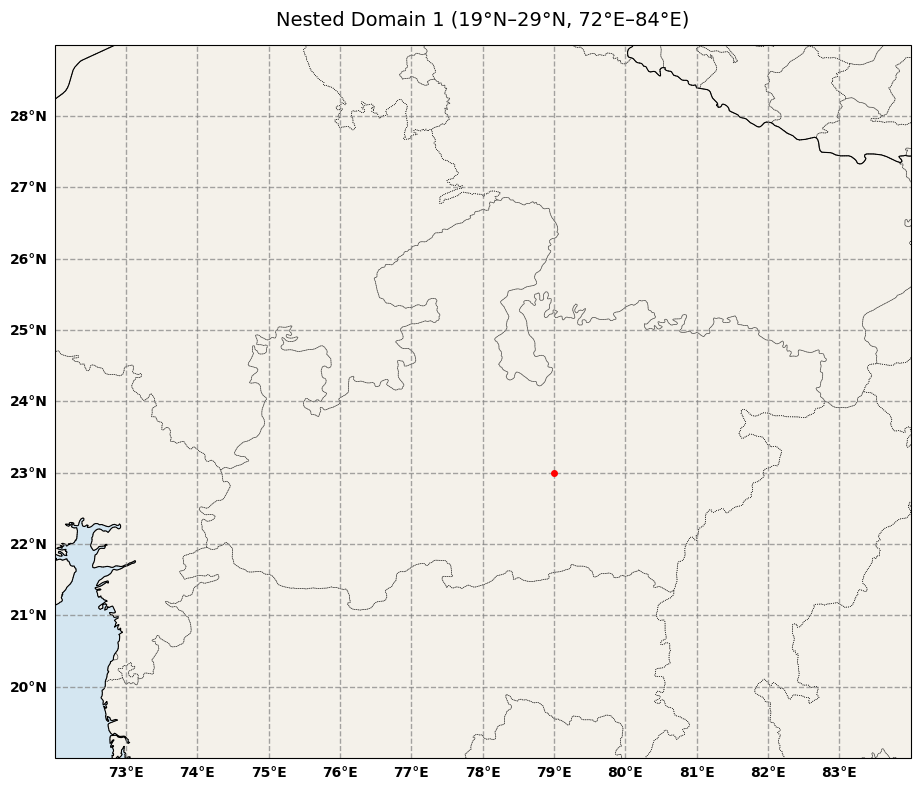

In [28]:
mid_lon=79
mid_lat=23


import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# 1. Define your latitude and longitude limits [min_lon, max_lon, min_lat, max_lat]
# Example: Central India / Madhya Pradesh region
lon_min, lon_max = n1_lon_min, n1_lon_max
lat_min, lat_max = n1_lat_min, n1_lat_max

# 2. Set up the figure and map projection
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# 3. Apply the coordinate limits to the map
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# 4. Add basic geographic features for context
ax.add_feature(cfeature.LAND, facecolor="#f4f1ea")
ax.add_feature(cfeature.OCEAN, facecolor="#d4e6f1")
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle="-", linewidth=0.8)
ax.add_feature(
    cfeature.STATES, linestyle=":", linewidth=0.5
)  # State/province borders

# 5. Add gridlines highlighting whole-number lat/lon
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=1.0,
    color="gray",
    alpha=0.7,
    linestyle="--",
)
# 6. Add center lat/lon
ax.plot(
    mid_lon,
    mid_lat,
    marker='o',
    color='red',
    markersize=4,
    transform=ccrs.PlateCarree(),
)

# Turn off labels on the top and right edges for a cleaner look
gl.top_labels = False
gl.right_labels = False

# Force gridlines to appear strictly at whole numbers (1-degree steps)
gl.xlocator = mticker.FixedLocator(np.arange(lon_min, lon_max + 1, 1))
gl.ylocator = mticker.FixedLocator(np.arange(lat_min, lat_max + 1, 1))

# Format the labels as whole numbers with degree symbols
gl.xformatter = mticker.FuncFormatter(lambda x, pos: f"{int(x)}°E")
gl.yformatter = mticker.FuncFormatter(lambda y, pos: f"{int(y)}°N")

# Style the gridline text
gl.xlabel_style = {"size": 10, "weight": "bold", "color": "black"}
gl.ylabel_style = {"size": 10, "weight": "bold", "color": "black"}

plt.title(
        f"Nested Domain 1 ({lat_min}°N–{lat_max}°N, {lon_min}°E–{lon_max}°E)",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

C:\Users\mohan\anaconda3\envs\Geopandas\Lib\site-packages\cartopy\io\__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
C:\Users\mohan\anaconda3\envs\Geopandas\Lib\site-packages\cartopy\io\__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


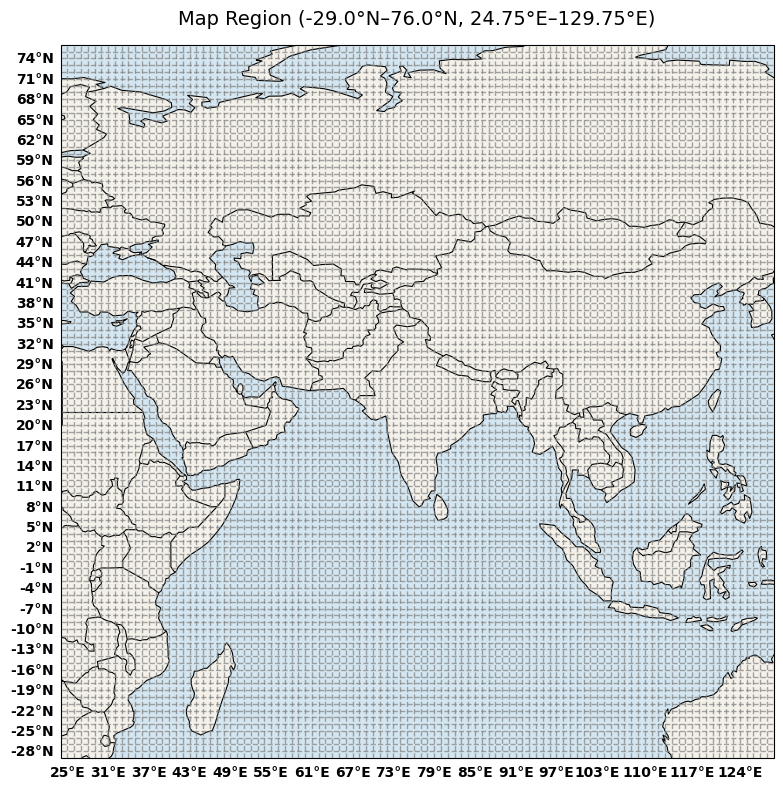

In [37]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# 1. Define your latitude and longitude limits [min_lon, max_lon, min_lat, max_lat]
# Example: Central India / Madhya Pradesh region
lon_min, lon_max = a[0], a[1]
lat_min, lat_max = a[2], a[3]

# 2. Set up the figure and map projection
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# 3. Apply the coordinate limits to the map
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# 4. Add basic geographic features for context
ax.add_feature(cfeature.LAND, facecolor="#f4f1ea")
ax.add_feature(cfeature.OCEAN, facecolor="#d4e6f1")
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle="-", linewidth=0.8)
ax.add_feature(
    cfeature.STATES, linestyle=":", linewidth=0.5
)  # State/province borders

# 5. Add gridlines highlighting whole-number lat/lon
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=1.0,
    color="gray",
    alpha=0.7,
    linestyle="--",
)

# Turn off labels on the top and right edges for a cleaner look
gl.top_labels = False
gl.right_labels = False

# Force gridlines to appear strictly at whole numbers (1-degree steps)
gl.xlocator = mticker.FixedLocator(np.arange(lon_min, lon_max + 1, 1))
gl.ylocator = mticker.FixedLocator(np.arange(lat_min, lat_max + 1, 1))

# Format the labels as whole numbers with degree symbols
gl.xformatter = mticker.FuncFormatter(lambda x, pos: f"{int(x)}°E")
gl.yformatter = mticker.FuncFormatter(lambda y, pos: f"{int(y)}°N")

# Style the gridline text
gl.xlabel_style = {"size": 10, "weight": "bold", "color": "black"}
gl.ylabel_style = {"size": 10, "weight": "bold", "color": "black"}

plt.title(
    f"Map Region ({lat_min}°N–{lat_max}°N, {lon_min}°E–{lon_max}°E)",
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

In [185]:
# Find the multiples between the numbers
# # Define the range
start = 55660
end = 55669

sum_of_multiples = 0
multiples = []

# Iterate through the range
for i in range(start, end + 1):
  if i % 3 == 0:
    multiples.append(i)
    sum_of_multiples += i

print("Multiples of 3:", multiples)
print("Sum of Multiples:", sum_of_multiples)

Multiples of 3: [55662, 55665, 55668]
Sum of Multiples: 166995


In [ ]:
# Parent grid calculations
# p_lonmin, p_lonmax = mid_lon-p_ext,mid_lon+p_ext
# p_latmin, p_latmax = mid_lon-p_ext,mid_lon+p_ext

p_resol = 0.5
p_lat_half_extent = 204/2 # number of step will be double of it
p_lon_half_extent = 204/2 # number of step will be double of it

p_lons = mid_lon + np.arange(-p_lon_half_extent, p_lon_half_extent + 1) * p_resol
p_lats = mid_lat + np.arange(-p_lat_half_extent, p_lat_half_extent + 1) * p_resol
print('Min Lon:',p_lons.min(),'Max Lon:',p_lons.max())
print('Min Lat:',p_lats.min(),'Max Lat:',p_lats.max())
print('Lons(parent:e_we):',p_lons.shape)
print('Lats(parent:e_sn):',p_lats.shape)

In [31]:
np.array(a[2])

array([-29. , -28.5, -28. , -27.5, -27. , -26.5, -26. , -25.5, -25. ,
       -24.5, -24. , -23.5, -23. , -22.5, -22. , -21.5, -21. , -20.5,
       -20. , -19.5, -19. , -18.5, -18. , -17.5, -17. , -16.5, -16. ,
       -15.5, -15. , -14.5, -14. , -13.5, -13. , -12.5, -12. , -11.5,
       -11. , -10.5, -10. ,  -9.5,  -9. ,  -8.5,  -8. ,  -7.5,  -7. ,
        -6.5,  -6. ,  -5.5,  -5. ,  -4.5,  -4. ,  -3.5,  -3. ,  -2.5,
        -2. ,  -1.5,  -1. ,  -0.5,   0. ,   0.5,   1. ,   1.5,   2. ,
         2.5,   3. ,   3.5,   4. ,   4.5,   5. ,   5.5,   6. ,   6.5,
         7. ,   7.5,   8. ,   8.5,   9. ,   9.5,  10. ,  10.5,  11. ,
        11.5,  12. ,  12.5,  13. ,  13.5,  14. ,  14.5,  15. ,  15.5,
        16. ,  16.5,  17. ,  17.5,  18. ,  18.5,  19. ,  19.5,  20. ,
        20.5,  21. ,  21.5,  22. ,  22.5,  23. ,  23.5,  24. ,  24.5,
        25. ,  25.5,  26. ,  26.5,  27. ,  27.5,  28. ,  28.5,  29. ,
        29.5,  30. ,  30.5,  31. ,  31.5,  32. ,  32.5,  33. ,  33.5,
        34. ,  34.5,